# Customer Churn Prediction Using Machine Learning

## Project Overview
Customer churn prediction is a machine learning project designed to identify customers who are likely to leave a subscription-based service.

The goal is to analyze customer data, build a classification model, evaluate its performance, and identify opportunities for improving customer retention.

## Business Problem
Customer churn can reduce recurring revenue and increase customer acquisition costs. Predicting potential churners can help businesses prioritize retention campaigns and make data-driven decisions.

## Project Objectives
- Explore and understand customer data.
- Clean and preprocess the dataset.
- Perform exploratory data analysis (EDA).
- Train a machine learning classification model.
- Evaluate performance using appropriate classification metrics.
- Analyze false negatives and other prediction errors.
- Develop actionable business recommendations.

## Model Evaluation
The final model was evaluated on a held-out test set.

- **Accuracy:** 80.55%
- **Precision:** 67.12%
- **Recall:** 52.41%
- **F1-score:** 58.86%
- **ROC-AUC:** 84.69%

## Key Finding
The model missed 178 actual churners in the test set. Of these, 133 had month-to-month contracts. This highlights an opportunity to investigate customer retention strategies and improve churn detection.

## Tools & Technologies
Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn, CatBoost, and Google Colab.

## Important Limitation
The model does not identify every customer who will churn. Its predictions should support, rather than replace, business judgment. Further validation is needed before real-world deployment.


## 1. Import Libraries

In [79]:

# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning evaluation
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Display settings
pd.set_option("display.max_columns", None)

print("Libraries imported successfully!")


Libraries imported successfully!


## 2. Load Dataset

In [80]:

import kagglehub
import os

# Download the Telco Customer Churn dataset
path = kagglehub.dataset_download("blastchar/telco-customer-churn")

# Find the CSV file
csv_files = [
    os.path.join(root, file)
    for root, _, files in os.walk(path)
    for file in files
    if file.endswith(".csv")
]

print("Dataset files found:", csv_files)


Using Colab cache for faster access to the 'telco-customer-churn' dataset.
Dataset files found: ['/kaggle/input/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv']


In [81]:

df = pd.read_csv(csv_files[0])

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Data Quality Check

In [82]:

# Check dataset information
print("Dataset Information:")
df.info()

print("\nMissing Values:")
display(
    df.isnull().sum()
    .to_frame(name="Missing Values")
    .query("`Missing Values` > 0")
)

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nTarget Variable Distribution:")
display(df["Churn"].value_counts())

print("\nTarget Variable Percentage:")
display(
    (df["Churn"].value_counts(normalize=True) * 100)
    .round(2)
    .rename("Percentage")
)


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  704

,Missing Values



Duplicate Rows: 0

Target Variable Distribution:


,count
Churn,
No,5174
Yes,1869



Target Variable Percentage:


,Percentage
Churn,
No,73.46
Yes,26.54


## 4. Data Cleaning

In [83]:

# Keep the original dataset unchanged
df_clean = df.copy()

# Remove leading/trailing whitespace from text columns
text_cols = df_clean.select_dtypes(include="object").columns

for col in text_cols:
    df_clean[col] = df_clean[col].str.strip()

# Convert TotalCharges to numeric
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"],
    errors="coerce"
)

# Check missing values created during conversion
print("Missing TotalCharges after conversion:",
      df_clean["TotalCharges"].isnull().sum())

# Inspect rows where TotalCharges is missing
display(
    df_clean[df_clean["TotalCharges"].isnull()]
)

# Check updated data types
print("\nUpdated TotalCharges dtype:",
      df_clean["TotalCharges"].dtype)


Missing TotalCharges after conversion: 11


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No



Updated TotalCharges dtype: float64


## 4.1 Handle Missing Values

In [84]:

# Fill missing TotalCharges for customers with zero tenure
df_clean.loc[
    (df_clean["TotalCharges"].isna()) &
    (df_clean["tenure"] == 0),
    "TotalCharges"
] = 0

# Verify data cleaning
print("Missing values remaining:", df_clean.isnull().sum().sum())
print("Duplicate rows:", df_clean.duplicated().sum())
print("Dataset shape:", df_clean.shape)
print("TotalCharges dtype:", df_clean["TotalCharges"].dtype)


Missing values remaining: 0
Duplicate rows: 0
Dataset shape: (7043, 21)
TotalCharges dtype: float64


## 5. Exploratory Data Analysis (EDA)

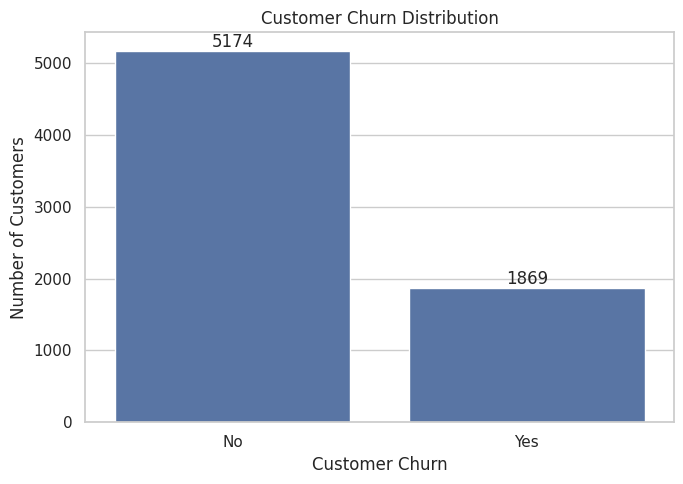

Churn percentage:


,Percentage
Churn,
No,73.46
Yes,26.54


In [85]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(7, 5))
ax = sns.countplot(data=df_clean, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Customer Churn")
plt.ylabel("Number of Customers")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

print("Churn percentage:")
display(
    (df_clean["Churn"].value_counts(normalize=True) * 100)
    .round(2)
    .rename("Percentage")
)


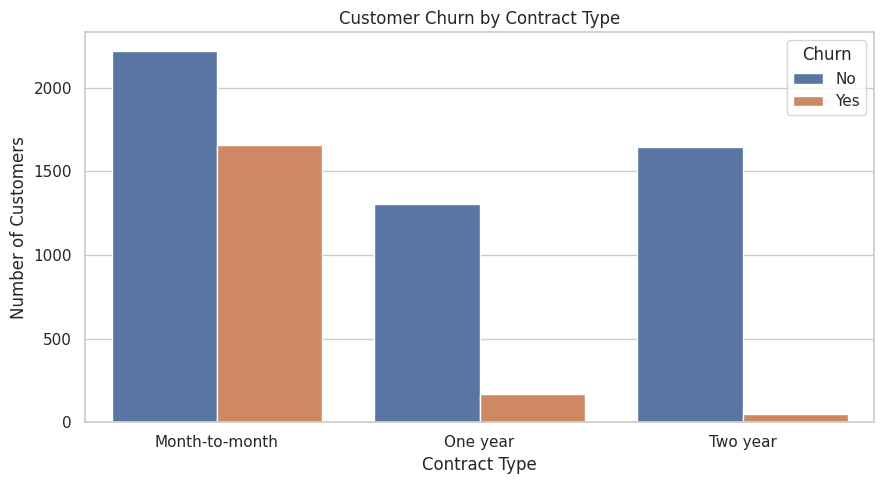

In [86]:

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df_clean,
    x="Contract",
    hue="Churn",
    order=["Month-to-month", "One year", "Two year"]
)

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.legend(title="Churn")

plt.tight_layout()
plt.show()


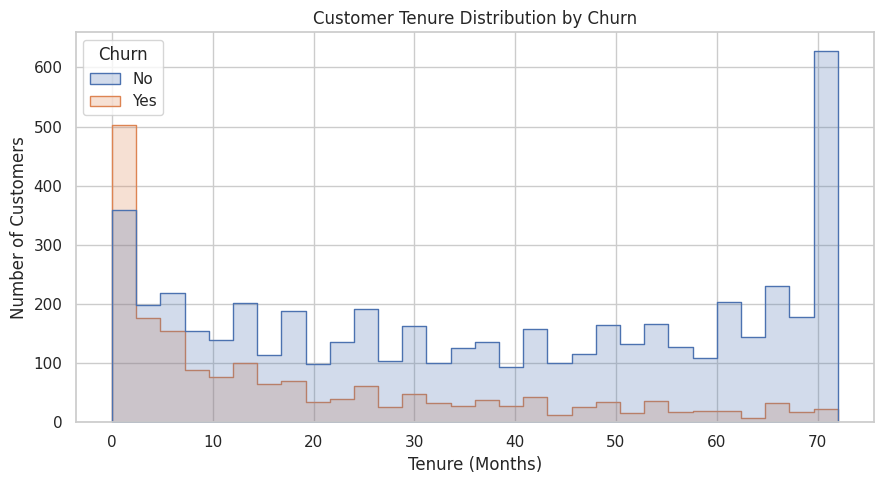

In [87]:

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df_clean,
    x="tenure",
    hue="Churn",
    bins=30,
    multiple="layer",
    element="step"
)

plt.title("Customer Tenure Distribution by Churn")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()


## 5.2 Churn Rate Analysis

Churn Rate by Contract Type:


,Churn Rate (%)
Contract,
Month-to-month,42.71
One year,11.27
Two year,2.83


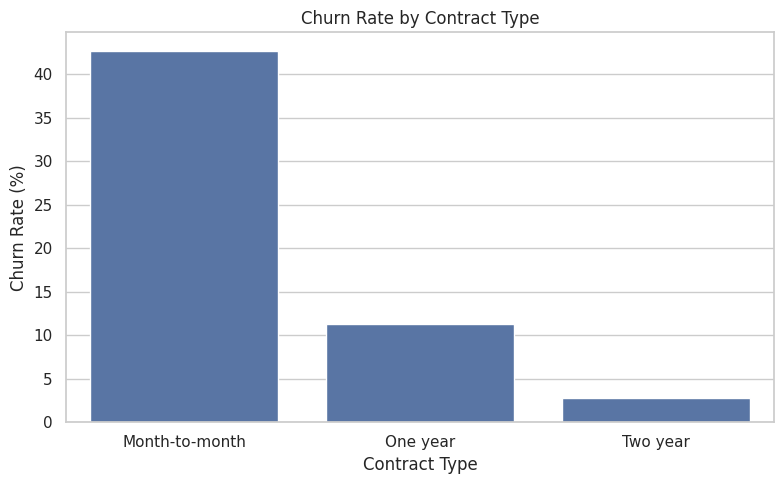

In [88]:

# Calculate churn rate for each contract type
contract_churn = (
    df_clean.groupby("Contract", observed=False)["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

print("Churn Rate by Contract Type:")
display(contract_churn.round(2).rename("Churn Rate (%)").to_frame())

# Visualize churn rates
plt.figure(figsize=(8, 5))

sns.barplot(
    x=contract_churn.index,
    y=contract_churn.values
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()


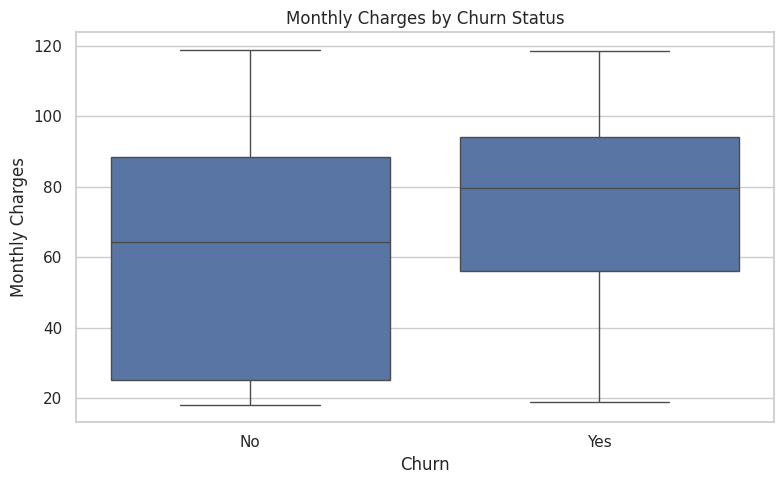

Average Monthly Charges by Churn:


,MonthlyCharges
Churn,
No,61.27
Yes,74.44


In [89]:

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.tight_layout()
plt.show()

print("Average Monthly Charges by Churn:")
display(
    df_clean.groupby("Churn", observed=False)["MonthlyCharges"]
    .mean()
    .round(2)
    .to_frame()
)


In [90]:

print("Average Tenure by Churn Status:")
display(
    df_clean.groupby("Churn", observed=False)["tenure"]
    .mean()
    .round(2)
    .to_frame()
)


Average Tenure by Churn Status:


,tenure
Churn,
No,37.57
Yes,17.98


### Key Exploratory Data Analysis Findings

- The dataset contains 7,043 customer records and 21 columns.
- Approximately 26.54% of customers in the dataset have churned.
- Contract type, customer tenure, and monthly charges are useful variables to investigate when studying churn patterns.
- Customers with different contract types may exhibit different churn rates, so group-level percentages are more informative than raw counts alone.
- Exploratory findings describe associations in the data and do not establish causation.

## 6. Feature Preprocessing

In [91]:

# Create a separate modeling dataset
model_df = df_clean.copy()

# Remove customer ID because it is an identifier, not a useful behavioral feature
model_df = model_df.drop(columns=["customerID"])

# Convert target variable to binary labels
model_df["Churn"] = model_df["Churn"].map({
    "No": 0,
    "Yes": 1
})

# Separate features and target
X = model_df.drop(columns=["Churn"])
y = model_df["Churn"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
display(y.value_counts().rename(index={0: "No Churn", 1: "Churn"}))

print("\nFeature data types:")
display(X.dtypes.to_frame("Data Type"))


Features shape: (7043, 19)
Target shape: (7043,)

Target distribution:


,count
Churn,
No Churn,5174
Churn,1869



Feature data types:


,Data Type
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object
OnlineBackup,object


## 7. Train-Test Split

The dataset is divided into training and testing subsets to evaluate the model on unseen data. Stratified splitting helps preserve the original churn-class distribution across both subsets.

The test set is reserved for final evaluation. Model selection and hyperparameter tuning should be performed using training data and validation procedures.

In [92]:

print("Training features:", X_train_cb.shape)
print("Testing features:", X_test_cb.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)


Training features: (5634, 19)
Testing features: (1409, 19)
Training target: (5634,)
Testing target: (1409,)


## 8. Model Training

CatBoost was used to build a binary classification model for customer churn prediction. The model estimates the likelihood that a customer will leave the service.

The training data was used to fit the model, while the held-out test set was reserved for final performance evaluation.

CatBoost supports categorical features and can model nonlinear relationships between customer characteristics and churn outcomes.

## 9. Final Model Evaluation

In [93]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Use the final predictions already generated by your trained model
print("Final Test Results")
print("-" * 35)
print(f"Accuracy : {accuracy_score(y_test, test_pred):.4f}")
print(f"Precision: {precision_score(y_test, test_pred, zero_division=0):.4f}")
print(f"Recall   : {recall_score(y_test, test_pred, zero_division=0):.4f}")
print(f"F1-score : {f1_score(y_test, test_pred, zero_division=0):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, test_prob):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    test_pred,
    target_names=["No Churn", "Churn"],
    zero_division=0
))


Final Test Results
-----------------------------------
Accuracy : 0.8055
Precision: 0.6712
Recall   : 0.5241
F1-score : 0.5886
ROC-AUC  : 0.8469

Confusion Matrix:
[[939  96]
 [178 196]]

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.84      0.91      0.87      1035
       Churn       0.67      0.52      0.59       374

    accuracy                           0.81      1409
   macro avg       0.76      0.72      0.73      1409
weighted avg       0.80      0.81      0.80      1409



## 10. Confusion Matrix Analysis

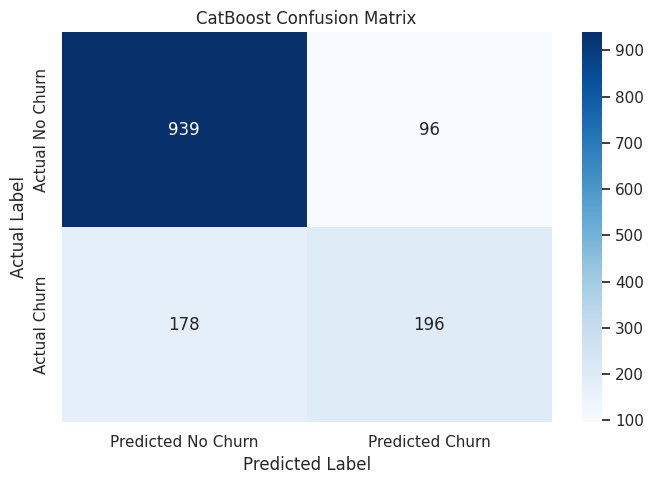

In [94]:

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, test_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted No Churn", "Predicted Churn"],
    yticklabels=["Actual No Churn", "Actual Churn"]
)

plt.title("CatBoost Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()


### Confusion Matrix Interpretation

The final model was evaluated on 1,409 customers.

- **True Negatives (939):** Correctly identified customers who did not churn.
- **False Positives (96):** Customers predicted to churn who actually stayed.
- **False Negatives (178):** Customers who churned but were not identified by the model.
- **True Positives (196):** Customers correctly identified as churners.

### Business Implications

The model correctly identified 196 out of 374 actual churners, achieving a churn recall of 52.41%. However, it missed 178 churners, indicating that some at-risk customers may not receive targeted retention efforts.

The model's precision of 67.12% means that approximately two-thirds of its positive churn predictions were correct. Whether this performance is useful depends on the cost of retention campaigns and the financial impact of losing customers.

The ROC-AUC score of 0.8469 indicates good ability to rank churners above non-churners across different classification thresholds, although performance at the chosen threshold still leaves room for improvement.

## 11. Error Analysis

In [95]:

# Create a dataframe containing actual outcomes and model predictions
error_df = X_test_cb.copy()

error_df["ActualChurn"] = y_test.to_numpy()
error_df["PredictedChurn"] = test_pred
error_df["ChurnProbability"] = test_prob

# Identify customers who churned but were missed by the model
missed_churners = error_df[
    (error_df["ActualChurn"] == 1) &
    (error_df["PredictedChurn"] == 0)
].copy()

print("Missed churners:", len(missed_churners))

print("\nMissed churners by contract:")
display(missed_churners["Contract"].value_counts().to_frame("Count"))

print("\nAverage tenure:")
print("Missed churners:", round(missed_churners["tenure"].mean(), 2))
print("All test customers:", round(error_df["tenure"].mean(), 2))

print("\nAverage monthly charges:")
print("Missed churners:", round(missed_churners["MonthlyCharges"].mean(), 2))
print("All test customers:", round(error_df["MonthlyCharges"].mean(), 2))


Missed churners: 178

Missed churners by contract:


,Count
Contract,
Month-to-month,133
One year,36
Two year,9



Average tenure:
Missed churners: 25.4
All test customers: 31.92

Average monthly charges:
Missed churners: 66.97
All test customers: 64.09


### Error Analysis Findings

The model failed to identify 178 customers who actually churned.

Among these missed churners, 133 had month-to-month contracts, 36 had one-year contracts, and 9 had two-year contracts. The missed churners had an average tenure of approximately 25.4 months and average monthly charges of $66.97.

These results suggest that the model's missed predictions deserve further investigation, particularly among month-to-month customers. However, counts alone do not establish which contract group has the highest miss rate; that comparison requires considering the total number of actual churners in each group.

### Limitations

These findings are descriptive and do not establish causation. Contract-specific recall should be interpreted cautiously where the number of actual churners is small.

In [96]:

print("Model variable available:", "model_cb" in globals())
print("CatBoost model variable available:", "catboost_model" in globals())


Model variable available: False
CatBoost model variable available: False


In [97]:

# Find trained model objects currently available in memory
for name, obj in globals().copy().items():
    try:
        if (
            callable(getattr(obj, "predict", None))
            and (
                callable(getattr(obj, "predict_proba", None))
                or "catboost" in type(obj).__module__.lower()
            )
        ):
            print(
                "Variable:", name,
                "| Model type:", type(obj).__name__,
                "| Module:", type(obj).__module__
            )
    except Exception:
        pass


Variable: _ | Model type: Pipeline | Module: sklearn.pipeline
Variable: Pipeline | Model type: ABCMeta | Module: abc
Variable: LogisticRegression | Model type: type | Module: builtins
Variable: lr_model | Model type: Pipeline | Module: sklearn.pipeline
Variable: RandomForestClassifier | Model type: ABCMeta | Module: abc
Variable: rf_model | Model type: Pipeline | Module: sklearn.pipeline
Variable: model | Model type: CatBoostClassifier | Module: catboost.core
Variable: HistGradientBoostingClassifier | Model type: ABCMeta | Module: abc
Variable: gb_model | Model type: Pipeline | Module: sklearn.pipeline
Variable: CatBoostClassifier | Model type: type | Module: builtins
Variable: cat_model | Model type: CatBoostClassifier | Module: catboost.core
Variable: RandomizedSearchCV | Model type: ABCMeta | Module: abc
Variable: base_model | Model type: CatBoostClassifier | Module: catboost.core
Variable: search | Model type: RandomizedSearchCV | Module: sklearn.model_selection._search
Variable: b

## 12. Save Final Model

In [98]:

import joblib
import os
from sklearn.metrics import accuracy_score

# Verify that the model reproduces the final predictions
check_pred = final_cat_model.predict(X_test_cb).reshape(-1)

print(
    "Predictions match:",
    (check_pred == test_pred).all()
)

print(
    "Verified accuracy:",
    round(accuracy_score(y_test, check_pred), 4)
)

# Save the trained model
model_path = "customer_churn_catboost.cbm"
final_cat_model.save_model(model_path)

print("Model saved:", os.path.abspath(model_path))
print("File size:", round(os.path.getsize(model_path) / 1024, 2), "KB")


Predictions match: True
Verified accuracy: 0.8055
Model saved: /content/customer_churn_catboost.cbm
File size: 230.37 KB


In [99]:
import kagglehub
path = kagglehub.dataset_download("blastchar/telco-customer-churn")

Using Colab cache for faster access to the 'telco-customer-churn' dataset.


In [100]:
import os

print("Dataset folder:", path)

for root, dirs, files in os.walk(path):
    for file in files:
        print(os.path.join(root, file))

Dataset folder: /kaggle/input/telco-customer-churn
/kaggle/input/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv


In [101]:
import pandas as pd
import os

csv_path = os.path.join(
    path,
    "WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

df = pd.read_csv(csv_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [102]:
print("Columns:")
print(df.columns.tolist())

print("\nData types:")
df.info()

Columns:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Data types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 no

In [103]:
# 1. Check missing values
print("Missing values per column:")
display(df.isnull().sum().sort_values(ascending=False))

# 2. Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# 3. Check duplicate customer IDs
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())

# 4. Check target variable distribution
print("\nChurn counts:")
display(df["Churn"].value_counts())

print("\nChurn percentages:")
display(
    (df["Churn"].value_counts(normalize=True) * 100).round(2)
)


Missing values per column:


,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0



Duplicate rows: 0
Duplicate customer IDs: 0

Churn counts:


,count
Churn,
No,5174
Yes,1869



Churn percentages:


,proportion
Churn,
No,73.46
Yes,26.54


In [104]:
print("TotalCharges data type:", df["TotalCharges"].dtype)

# Convert to numeric; invalid/blank values become NaN
total_charges_numeric = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

print(
    "Values that cannot be converted:",
    total_charges_numeric.isna().sum()
)

display(
    df.loc[
        total_charges_numeric.isna(),
        ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
    ].head(10)
)

TotalCharges data type: object
Values that cannot be converted: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [105]:
# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].astype(str).str.strip(),
    errors="coerce"
)

# Check missing values after conversion
print("Missing TotalCharges:", df["TotalCharges"].isna().sum())

# Inspect affected records
display(
    df.loc[
        df["TotalCharges"].isna(),
        ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
    ]
)

# Check tenure of affected records
print(
    "\nTenure values for missing TotalCharges:",
    df.loc[df["TotalCharges"].isna(), "tenure"].unique()
)

# Confirm data type
print("\nNew TotalCharges dtype:", df["TotalCharges"].dtype)

Missing TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No



Tenure values for missing TotalCharges: [0]

New TotalCharges dtype: float64


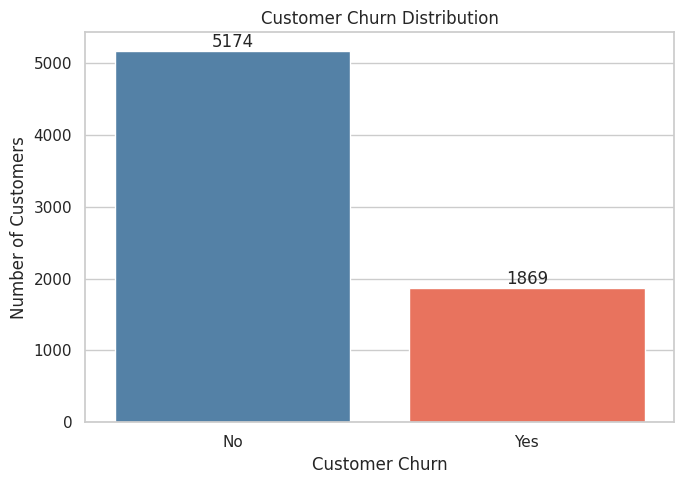

In [106]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df,
    x="Churn",
    hue="Churn",
    order=["No", "Yes"],
    palette=["steelblue", "tomato"],
    legend=False
)

plt.title("Customer Churn Distribution")
plt.xlabel("Customer Churn")
plt.ylabel("Number of Customers")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

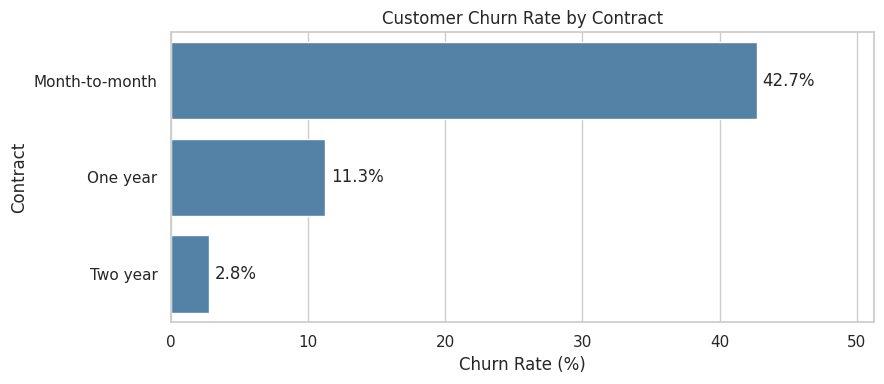

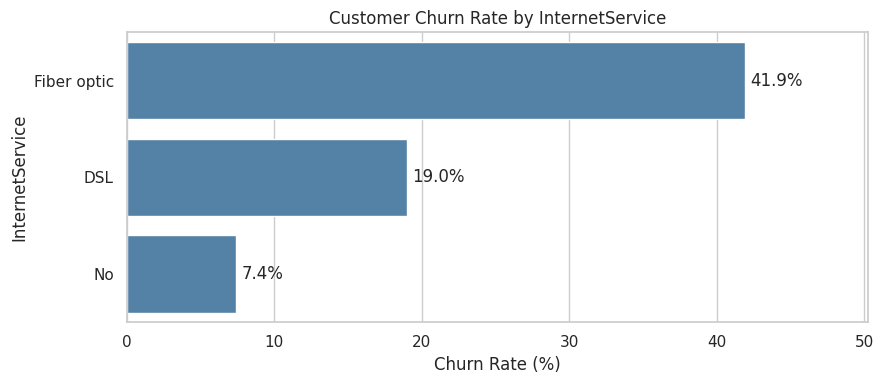

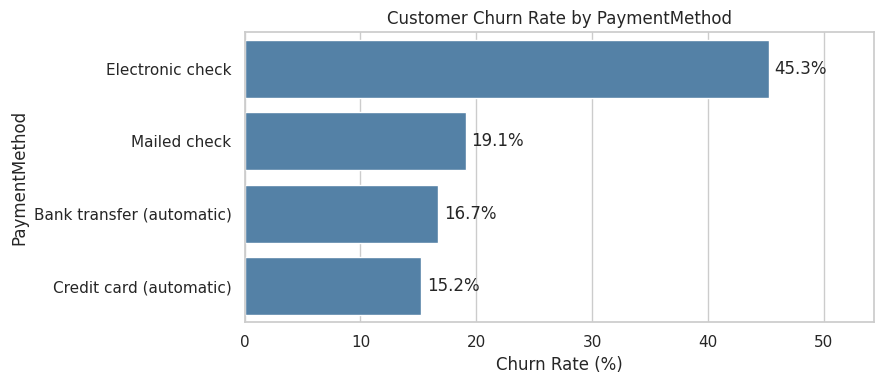

In [107]:
# Compare churn rate across important customer features

features = ["Contract", "InternetService", "PaymentMethod"]

for feature in features:
    churn_rate = (
        df.groupby(feature, observed=True)["Churn"]
        .apply(lambda x: (x == "Yes").mean() * 100)
        .sort_values(ascending=False)
    )

    plt.figure(figsize=(9, 4))
    ax = sns.barplot(
        x=churn_rate.values,
        y=churn_rate.index,
        color="steelblue"
    )

    ax.bar_label(
        ax.containers[0],
        fmt="%.1f%%",
        padding=4
    )

    plt.title(f"Customer Churn Rate by {feature}")
    plt.xlabel("Churn Rate (%)")
    plt.ylabel(feature)
    plt.xlim(0, min(100, churn_rate.max() * 1.2))
    plt.tight_layout()
    plt.show()

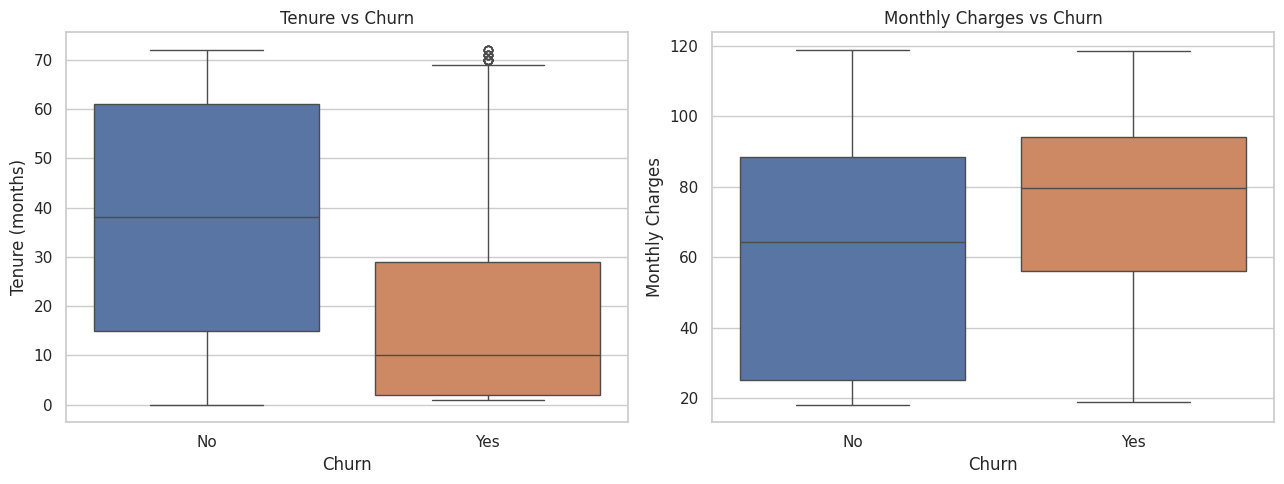

In [108]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure",
    hue="Churn",
    order=["No", "Yes"],
    ax=axes[0],
    legend=False
)
axes[0].set_title("Tenure vs Churn")
axes[0].set_xlabel("Churn")
axes[0].set_ylabel("Tenure (months)")

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges",
    hue="Churn",
    order=["No", "Yes"],
    ax=axes[1],
    legend=False
)
axes[1].set_title("Monthly Charges vs Churn")
axes[1].set_xlabel("Churn")
axes[1].set_ylabel("Monthly Charges")

plt.tight_layout()
plt.show()

In [109]:
# 1. Churn rate by contract
contract_churn = (
    df.groupby("Contract")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .round(2)
)

print("Churn rate by Contract (%):")
print(contract_churn)

# 2. Compare tenure and monthly charges
print("\nAverage customer tenure:")
print(df.groupby("Churn")["tenure"].mean().round(2))

print("\nAverage monthly charges:")
print(df.groupby("Churn")["MonthlyCharges"].mean().round(2))

# 3. Compare distributions using medians
print("\nMedian tenure:")
print(df.groupby("Churn")["tenure"].median())

print("\nMedian monthly charges:")
print(df.groupby("Churn")["MonthlyCharges"].median())

Churn rate by Contract (%):
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64

Average customer tenure:
Churn
No     37.57
Yes    17.98
Name: tenure, dtype: float64

Average monthly charges:
Churn
No     61.27
Yes    74.44
Name: MonthlyCharges, dtype: float64

Median tenure:
Churn
No     38.0
Yes    10.0
Name: tenure, dtype: float64

Median monthly charges:
Churn
No     64.425
Yes    79.650
Name: MonthlyCharges, dtype: float64


In [110]:
from sklearn.model_selection import train_test_split

# Customer ID is an identifier, not a useful prediction feature
X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"].map({"No": 0, "Yes": 1})

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget values:")
print(y.value_counts())

Features shape: (7043, 19)
Target shape: (7043,)

Target values:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [111]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

print("\nTraining churn rate:")
print(round(y_train.mean() * 100, 2), "%")

print("Testing churn rate:")
print(round(y_test.mean() * 100, 2), "%")

Training rows: 5634
Testing rows: 1409

Training churn rate:
26.54 %
Testing churn rate:
26.54 %


In [112]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [113]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Combine preprocessing and model into one pipeline
lr_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight=None,
        random_state=42
    ))
])

# Train using training data only
lr_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


Accuracy : 0.8055
Precision: 0.6572
Recall   : 0.5588
F1-score : 0.604
ROC-AUC  : 0.8419

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1035
       Churn       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



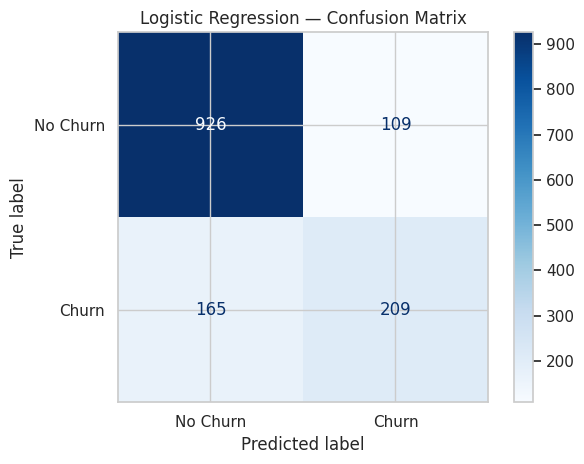

In [114]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Predictions on unseen test data
y_pred = lr_model.predict(X_test)
y_prob = lr_model.predict_proba(X_test)[:, 1]

print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall   :", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-score :", round(f1_score(y_test, y_pred, zero_division=0), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Churn", "Churn"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No Churn", "Churn"],
    cmap="Blues"
)

plt.title("Logistic Regression — Confusion Matrix")
plt.tight_layout()
plt.show()

In [115]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [116]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd

models = {
    "Logistic Regression": lr_model,
    "Random Forest": rf_model
}

results = []

for name, model in models.items():
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-score": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, prob)
    })

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(4))

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.8055,0.6572,0.5588,0.6040,0.8419
Random Forest,0.7842,0.5845,0.6471,0.6142,0.8347


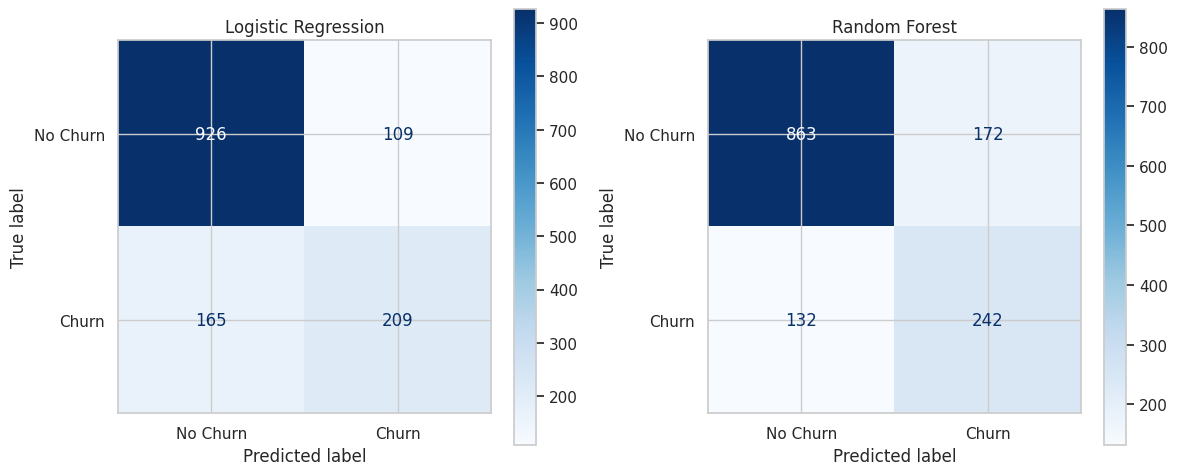

In [117]:

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, model) in zip(
    axes,
    [("Logistic Regression", lr_model),
     ("Random Forest", rf_model)]
):
    ConfusionMatrixDisplay.from_estimator(
        model,
        X_test,
        y_test,
        display_labels=["No Churn", "Churn"],
        cmap="Blues",
        ax=ax
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()


In [118]:

from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

# Training data se validation set alag karo
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Validation split par models dobara train karo
lr_model.fit(X_fit, y_fit)
rf_model.fit(X_fit, y_fit)

rows = []

for name, model in [
    ("Logistic Regression", lr_model),
    ("Random Forest", rf_model)
]:
    probabilities = model.predict_proba(X_val)[:, 1]

    for threshold in [0.30, 0.35, 0.40, 0.45, 0.50]:
        predictions = (probabilities >= threshold).astype(int)

        rows.append({
            "Model": name,
            "Threshold": threshold,
            "Precision": precision_score(
                y_val, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_val, predictions, zero_division=0
            ),
            "F1-score": f1_score(
                y_val, predictions, zero_division=0
            )
        })

threshold_results = pd.DataFrame(rows)
display(threshold_results.round(3))


,Model,Threshold,Precision,Recall,F1-score
0,Logistic Regression,0.30,0.543,0.756,0.632
1,Logistic Regression,0.35,0.581,0.709,0.639
2,Logistic Regression,0.40,0.617,0.669,0.642
3,Logistic Regression,0.45,0.659,0.602,0.629
4,Logistic Regression,0.50,0.694,0.545,0.610
5,Random Forest,0.30,0.483,0.816,0.607
6,Random Forest,0.35,0.512,0.779,0.618
7,Random Forest,0.40,0.531,0.736,0.617
8,Random Forest,0.45,0.572,0.692,0.626
9,Random Forest,0.50,0.604,0.649,0.626


In [119]:

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# HistGradientBoosting ko dense encoded features chahiye
dense_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ],
    sparse_threshold=0
)

gb_model = Pipeline([
    ("preprocessor", dense_preprocessor),
    ("classifier", HistGradientBoostingClassifier(
        max_iter=200,
        learning_rate=0.08,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        random_state=42
    ))
])

# Validation split par train karo
gb_model.fit(X_fit, y_fit)

# Threshold 0.50 par validation performance
val_pred = gb_model.predict(X_val)
val_prob = gb_model.predict_proba(X_val)[:, 1]

print("Gradient Boosting — Validation Results")
print("Accuracy :", round(accuracy_score(y_val, val_pred), 4))
print("Precision:", round(precision_score(y_val, val_pred), 4))
print("Recall   :", round(recall_score(y_val, val_pred), 4))
print("F1-score :", round(f1_score(y_val, val_pred), 4))
print("ROC-AUC  :", round(roc_auc_score(y_val, val_prob), 4))


Gradient Boosting — Validation Results
Accuracy : 0.8057
Precision: 0.6923
Recall   : 0.4816
F1-score : 0.568
ROC-AUC  : 0.8461


In [120]:

%pip -q install catboost


In [121]:

from catboost import CatBoostClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)
import pandas as pd

# CatBoost categorical columns ko directly handle kar sakta hai
X_fit_cb = X_fit.copy()
X_val_cb = X_val.copy()

cat_cols = X_fit_cb.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# Categorical values ko consistent string format mein rakho
for col in cat_cols:
    X_fit_cb[col] = X_fit_cb[col].fillna("Missing").astype(str)
    X_val_cb[col] = X_val_cb[col].fillna("Missing").astype(str)

# TotalCharges jaisi numeric columns ke missing values fill karo
num_cols = X_fit_cb.select_dtypes(include=["number"]).columns

for col in num_cols:
    median_value = X_fit_cb[col].median()
    X_fit_cb[col] = X_fit_cb[col].fillna(median_value)
    X_val_cb[col] = X_val_cb[col].fillna(median_value)

cat_model = CatBoostClassifier(
    iterations=1000,
    depth=6,
    learning_rate=0.03,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=42,
    verbose=0,
    allow_writing_files=False
)

cat_model.fit(
    X_fit_cb,
    y_fit,
    cat_features=cat_cols,
    eval_set=(X_val_cb, y_val),
    early_stopping_rounds=100,
    verbose=False
)

val_pred = cat_model.predict(X_val_cb).astype(int).ravel()
val_prob = cat_model.predict_proba(X_val_cb)[:, 1]

print("CatBoost — Validation Results")
print("Accuracy :", round(accuracy_score(y_val, val_pred), 4))
print("Precision:", round(precision_score(y_val, val_pred, zero_division=0), 4))
print("Recall   :", round(recall_score(y_val, val_pred, zero_division=0), 4))
print("F1-score :", round(f1_score(y_val, val_pred, zero_division=0), 4))
print("ROC-AUC  :", round(roc_auc_score(y_val, val_prob), 4))
print("Best iteration:", cat_model.best_iteration_)


CatBoost — Validation Results
Accuracy : 0.8181
Precision: 0.7117
Recall   : 0.5284
F1-score : 0.6065
ROC-AUC  : 0.8498
Best iteration: 205


In [ ]:

from catboost import CatBoostClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
)

# cat_features constructor se hata diya hai
base_model = CatBoostClassifier(
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=42,
    verbose=0,
    allow_writing_files=False,
    thread_count=1
)

param_dist = {
    "iterations": [300, 500, 700, 900],
    "depth": [4, 5, 6, 7, 8],
    "learning_rate": [0.02, 0.03, 0.05, 0.08],
    "l2_leaf_reg": [3, 5, 7, 9, 11],
    "random_strength": [0, 0.5, 1, 2]
}

search = RandomizedSearchCV(
    estimator=base_model,
    param_distributions=param_dist,
    n_iter=20,
    scoring="accuracy",
    cv=cv,
    random_state=42,
    n_jobs=1,
    verbose=1,
    refit=True
)

# Categorical columns ko fit ke waqt pass karo
search.fit(
    X_fit_cb,
    y_fit,
    cat_features=cat_cols
)

print("Best CV accuracy:", round(search.best_score_, 4))
print("Best parameters:")
print(search.best_params_)

best_model = search.best_estimator_

val_pred = best_model.predict(X_val_cb).astype(int).ravel()
val_prob = best_model.predict_proba(X_val_cb)[:, 1]

print("\nTuned CatBoost — Validation Results")
print("Accuracy :", round(accuracy_score(y_val, val_pred), 4))
print("Precision:", round(precision_score(y_val, val_pred, zero_division=0), 4))
print("Recall   :", round(recall_score(y_val, val_pred, zero_division=0), 4))
print("F1-score :", round(f1_score(y_val, val_pred, zero_division=0), 4))
print("ROC-AUC  :", round(roc_auc_score(y_val, val_prob), 4))


Fitting 5 folds for each of 20 candidates, totalling 100 fits


In [ ]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)
from scipy.stats import randint

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ))
])

param_dist = {
    "classifier__n_estimators": [200, 300, 500, 700],
    "classifier__max_depth": [None, 8, 12, 16, 20, 25],
    "classifier__min_samples_split": randint(2, 20),
    "classifier__min_samples_leaf": randint(1, 10),
    "classifier__max_features": ["sqrt", "log2", 0.8],
    "classifier__class_weight": [None, "balanced", "balanced_subsample"]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_dist,
    n_iter=20,
    scoring="accuracy",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True
)

rf_search.fit(X_fit, y_fit)

print("Best CV accuracy:", round(rf_search.best_score_, 4))
print("Best parameters:")
print(rf_search.best_params_)

best_rf = rf_search.best_estimator_

val_pred = best_rf.predict(X_val)
val_prob = best_rf.predict_proba(X_val)[:, 1]

print("\nTuned Random Forest — Validation Results")
print("Accuracy :", round(accuracy_score(y_val, val_pred), 4))
print("Precision:", round(precision_score(y_val, val_pred, zero_division=0), 4))
print("Recall   :", round(recall_score(y_val, val_pred, zero_division=0), 4))
print("F1-score :", round(f1_score(y_val, val_pred, zero_division=0), 4))
print("ROC-AUC  :", round(roc_auc_score(y_val, val_prob), 4))


In [ ]:

%pip -q install xgboost


In [ ]:

from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=500,
        max_depth=3,
        learning_rate=0.03,
        min_child_weight=3,
        subsample=0.85,
        colsample_bytree=0.85,
        reg_lambda=3,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

xgb_model.fit(X_fit, y_fit)

val_pred = xgb_model.predict(X_val)
val_prob = xgb_model.predict_proba(X_val)[:, 1]

print("XGBoost — Validation Results")
print("Accuracy :", round(accuracy_score(y_val, val_pred), 4))
print("Precision:", round(precision_score(y_val, val_pred, zero_division=0), 4))
print("Recall   :", round(recall_score(y_val, val_pred, zero_division=0), 4))
print("F1-score :", round(f1_score(y_val, val_pred, zero_division=0), 4))
print("ROC-AUC  :", round(roc_auc_score(y_val, val_prob), 4))


In [ ]:

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Validation probabilities from the trained XGBoost model
val_prob = xgb_model.predict_proba(X_val)[:, 1]

rows = []

for threshold in np.arange(0.10, 0.91, 0.02):
    pred = (val_prob >= threshold).astype(int)

    rows.append({
        "Threshold": round(float(threshold), 2),
        "Accuracy": accuracy_score(y_val, pred),
        "Precision": precision_score(y_val, pred, zero_division=0),
        "Recall": recall_score(y_val, pred, zero_division=0),
        "F1-score": f1_score(y_val, pred, zero_division=0)
    })

threshold_df = pd.DataFrame(rows)
threshold_df = threshold_df.sort_values(
    ["Accuracy", "Recall"],
    ascending=[False, False]
).reset_index(drop=True)

display(threshold_df.head(10).round(4))


In [ ]:

import pandas as pd

# Feature names after preprocessing
feature_names = xgb_model.named_steps["preprocessor"].get_feature_names_out()
importances = xgb_model.named_steps["classifier"].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

display(importance_df.head(20).round(4))


In [ ]:

import pandas as pd
from sklearn.model_selection import train_test_split

# Original data ki copy
df_fe = df.copy()

# 1. Tenure groups
df_fe["TenureGroup"] = pd.cut(
    df_fe["tenure"],
    bins=[-1, 12, 24, 48, float("inf")],
    labels=["0-12", "13-24", "25-48", "49+"]
).astype(str)

# 2. Average monthly spend across tenure
df_fe["AvgChargePerMonth"] = (
    df_fe["TotalCharges"] / df_fe["tenure"].replace(0, pd.NA)
)

# 3. Number of additional services
service_cols = [
    "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies"
]

df_fe["NumServices"] = (
    df_fe[service_cols] == "Yes"
).sum(axis=1)

# Target and features
X_fe = df_fe.drop(columns=["Churn", "customerID"])
y_fe = df_fe["Churn"].map({"No": 0, "Yes": 1})

# Same split settings for fair comparison
X_train_fe, X_test_fe, y_train_fe, y_test_fe = train_test_split(
    X_fe, y_fe,
    test_size=0.20,
    random_state=42,
    stratify=y_fe
)

X_fit_fe, X_val_fe, y_fit_fe, y_val_fe = train_test_split(
    X_train_fe, y_train_fe,
    test_size=0.20,
    random_state=42,
    stratify=y_train_fe
)

print("New dataset shape:", X_fe.shape)
print("New features:", ["TenureGroup", "AvgChargePerMonth", "NumServices"])
print("Missing AvgChargePerMonth:", X_fe["AvgChargePerMonth"].isna().sum())


In [ ]:

from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)
from xgboost import XGBClassifier

xgb_fe = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=500,
        max_depth=3,
        learning_rate=0.03,
        min_child_weight=3,
        subsample=0.85,
        colsample_bytree=0.85,
        reg_lambda=3,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

xgb_fe.fit(X_fit_fe, y_fit_fe)

val_pred_fe = xgb_fe.predict(X_val_fe)
val_prob_fe = xgb_fe.predict_proba(X_val_fe)[:, 1]

print("Feature-engineered XGBoost — Validation Results")
print("Accuracy :", round(accuracy_score(y_val_fe, val_pred_fe), 4))
print("Precision:", round(precision_score(y_val_fe, val_pred_fe, zero_division=0), 4))
print("Recall   :", round(recall_score(y_val_fe, val_pred_fe, zero_division=0), 4))
print("F1-score :", round(f1_score(y_val_fe, val_pred_fe, zero_division=0), 4))
print("ROC-AUC  :", round(roc_auc_score(y_val_fe, val_prob_fe), 4))


In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_features_fe = X_fe.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features_fe = X_fe.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numeric_pipeline_fe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline_fe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_fe = ColumnTransformer([
    ("numeric", numeric_pipeline_fe, numeric_features_fe),
    ("categorical", categorical_pipeline_fe, categorical_features_fe)
])

# Existing xgb_fe pipeline mein correct preprocessor use karo
xgb_fe.set_params(preprocessor=preprocessor_fe)


In [ ]:

%pip -q install lightgbm


In [ ]:

from lightgbm import LGBMClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

lgbm_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LGBMClassifier(
        n_estimators=500,
        learning_rate=0.03,
        max_depth=-1,
        num_leaves=15,
        min_child_samples=30,
        reg_lambda=2.0,
        verbosity=-1,
        random_state=42,
        n_jobs=-1
    ))
])

lgbm_model.fit(X_fit, y_fit)

val_pred = lgbm_model.predict(X_val)
val_prob = lgbm_model.predict_proba(X_val)[:, 1]

print("LightGBM — Validation Results")
print("Accuracy :", round(accuracy_score(y_val, val_pred), 4))
print("Precision:", round(precision_score(y_val, val_pred, zero_division=0), 4))
print("Recall   :", round(recall_score(y_val, val_pred, zero_division=0), 4))
print("F1-score :", round(f1_score(y_val, val_pred, zero_division=0), 4))
print("ROC-AUC  :", round(roc_auc_score(y_val, val_prob), 4))


In [ ]:

from xgboost import XGBClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline

xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=1
    ))
])

param_dist = {
    "classifier__n_estimators": [300, 500, 700, 900],
    "classifier__max_depth": [2, 3, 4, 5],
    "classifier__learning_rate": [0.01, 0.02, 0.03, 0.05],
    "classifier__min_child_weight": [1, 3, 5, 7],
    "classifier__subsample": [0.7, 0.8, 0.9, 1.0],
    "classifier__colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "classifier__reg_lambda": [1, 3, 5, 10]
}

cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
)

xgb_search = RandomizedSearchCV(
    xgb_pipeline,
    param_distributions=param_dist,
    n_iter=25,
    scoring="roc_auc",
    cv=cv,
    random_state=42,
    n_jobs=1,
    verbose=1,
    refit=True
)

xgb_search.fit(X_fit, y_fit)

print("Best CV ROC-AUC:", round(xgb_search.best_score_, 4))
print("Best parameters:")
print(xgb_search.best_params_)

tuned_xgb = xgb_search.best_estimator_
val_pred = tuned_xgb.predict(X_val)
val_prob = tuned_xgb.predict_proba(X_val)[:, 1]

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

print("\nTuned XGBoost — Validation Results")
print("Accuracy :", round(accuracy_score(y_val, val_pred), 4))
print("Precision:", round(precision_score(y_val, val_pred, zero_division=0), 4))
print("Recall   :", round(recall_score(y_val, val_pred, zero_division=0), 4))
print("F1-score :", round(f1_score(y_val, val_pred, zero_division=0), 4))
print("ROC-AUC  :", round(roc_auc_score(y_val, val_prob), 4))


In [ ]:

from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report
import pandas as pd

# Baseline: har customer ke liye majority class predict karo
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_fit, y_fit)

dummy_pred = dummy.predict(X_val)

print("Majority-class baseline accuracy:",
      round(accuracy_score(y_val, dummy_pred), 4))

# Best current model vs baseline
models_to_compare = {
    "Majority baseline": dummy,
    "CatBoost": best_model,
    "Original XGBoost": xgb_model,
    "Tuned XGBoost": tuned_xgb
}

rows = []
for name, model in models_to_compare.items():
    pred = model.predict(X_val)
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, pred)
    })

display(pd.DataFrame(rows).sort_values("Accuracy", ascending=False).round(4))

print("\nCatBoost validation classification report:")
print(classification_report(
    y_val,
    best_model.predict(X_val),
    target_names=["No Churn", "Churn"],
    zero_division=0
))


In [ ]:

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

val_prob = xgb_model.predict_proba(X_val)[:, 1]

rows = []

for threshold in np.arange(0.10, 0.91, 0.01):
    pred = (val_prob >= threshold).astype(int)

    rows.append({
        "Threshold": round(float(threshold), 2),
        "Accuracy": accuracy_score(y_val, pred),
        "Precision": precision_score(y_val, pred, zero_division=0),
        "Recall": recall_score(y_val, pred, zero_division=0),
        "F1-score": f1_score(y_val, pred, zero_division=0)
    })

threshold_results = pd.DataFrame(rows)

best_rows = threshold_results.sort_values(
    "Accuracy", ascending=False
).head(10)

display(best_rows.round(4))


In [ ]:

# Data quality checks
print("Dataset shape:", df.shape)

print("\nTarget distribution:")
print(df["Churn"].value_counts(normalize=True).round(4))

print("\nMissing values:")
display(
    df.isna().sum()
       .loc[lambda x: x > 0]
       .sort_values(ascending=False)
       .to_frame("Missing_Count")
)

print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())

print("\nTrain/validation/test sizes:")
print("Training fit:", X_fit.shape, y_fit.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)


In [ ]:

from catboost import CatBoostClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

# Cross-validation only on fitting data
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cat_model_tune = CatBoostClassifier(
    loss_function="Logloss",
    eval_metric="Accuracy",
    random_seed=42,
    verbose=0,
    allow_writing_files=False,
    thread_count=1
)

param_dist = {
    "iterations": [200, 300, 500, 700, 900],
    "depth": [4, 5, 6, 7, 8],
    "learning_rate": [0.01, 0.02, 0.03, 0.05, 0.08],
    "l2_leaf_reg": [3, 5, 7, 9, 11],
    "random_strength": [0, 0.5, 1, 2, 5],
    "border_count": [64, 128, 254]
}

search_cat = RandomizedSearchCV(
    estimator=cat_model_tune,
    param_distributions=param_dist,
    n_iter=30,
    scoring="accuracy",
    cv=cv,
    random_state=42,
    n_jobs=1,
    verbose=1,
    refit=True
)

search_cat.fit(
    X_fit_cb,
    y_fit,
    cat_features=cat_cols
)

print("Best CV Accuracy:", round(search_cat.best_score_, 4))
print("Best Parameters:")
print(search_cat.best_params_)

# Evaluate the selected model on validation data
best_cat_tuned = search_cat.best_estimator_

val_pred = best_cat_tuned.predict(X_val_cb).astype(int).ravel()
val_prob = best_cat_tuned.predict_proba(X_val_cb)[:, 1]

print("\nTuned CatBoost — Validation Results")
print("Accuracy :", round(accuracy_score(y_val, val_pred), 4))
print("Precision:", round(precision_score(y_val, val_pred, zero_division=0), 4))
print("Recall   :", round(recall_score(y_val, val_pred, zero_division=0), 4))
print("F1-score :", round(f1_score(y_val, val_pred, zero_division=0), 4))
print("ROC-AUC  :", round(roc_auc_score(y_val, val_prob), 4))


In [ ]:

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Tuned CatBoost ki validation probabilities
cat_val_prob = best_cat_tuned.predict_proba(X_val_cb)[:, 1]

rows = []

for threshold in np.arange(0.20, 0.81, 0.01):
    pred = (cat_val_prob >= threshold).astype(int)

    rows.append({
        "Threshold": round(float(threshold), 2),
        "Accuracy": accuracy_score(y_val, pred),
        "Precision": precision_score(y_val, pred, zero_division=0),
        "Recall": recall_score(y_val, pred, zero_division=0),
        "F1-score": f1_score(y_val, pred, zero_division=0)
    })

cat_threshold_df = pd.DataFrame(rows)

display(
    cat_threshold_df.sort_values(
        ["Accuracy", "Recall"],
        ascending=[False, False]
    ).head(10).round(4)
)


In [ ]:

from catboost import CatBoostClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

configs = [
    {"iterations": 500, "depth": 4, "learning_rate": 0.03},
    {"iterations": 700, "depth": 4, "learning_rate": 0.02},
    {"iterations": 800, "depth": 5, "learning_rate": 0.02},
    {"iterations": 1000, "depth": 5, "learning_rate": 0.01},
    {"iterations": 700, "depth": 6, "learning_rate": 0.02},
    {"iterations": 1000, "depth": 6, "learning_rate": 0.01},
]

results = []
trained_models = {}

for i, config in enumerate(configs, start=1):
    model = CatBoostClassifier(
        **config,
        loss_function="Logloss",
        random_seed=42,
        l2_leaf_reg=3,
        random_strength=5,
        verbose=0,
        allow_writing_files=False,
        thread_count=-1
    )

    model.fit(X_fit_cb, y_fit, cat_features=cat_cols)

    pred = model.predict(X_val_cb).astype(int).ravel()
    prob = model.predict_proba(X_val_cb)[:, 1]

    results.append({
        "Experiment": i,
        **config,
        "Accuracy": accuracy_score(y_val, pred),
        "Precision": precision_score(y_val, pred, zero_division=0),
        "Recall": recall_score(y_val, pred, zero_division=0),
        "F1-score": f1_score(y_val, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, prob)
    })

    trained_models[i] = model

results_df = pd.DataFrame(results).sort_values(
    "Accuracy", ascending=False
).reset_index(drop=True)

display(results_df.round(4))


In [ ]:

import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)

# Experiment 2 ka trained model
best_cat_model = trained_models[2]

# Validation probabilities
cat_prob = best_cat_model.predict_proba(X_val_cb)[:, 1]

rows = []

for threshold in np.arange(0.30, 0.71, 0.01):
    pred = (cat_prob >= threshold).astype(int)

    rows.append({
        "Threshold": round(float(threshold), 2),
        "Accuracy": accuracy_score(y_val, pred),
        "Precision": precision_score(y_val, pred, zero_division=0),
        "Recall": recall_score(y_val, pred, zero_division=0),
        "F1-score": f1_score(y_val, pred, zero_division=0)
    })

threshold_results = pd.DataFrame(rows)

display(
    threshold_results
    .sort_values(["Accuracy", "Recall"], ascending=[False, False])
    .head(10)
    .round(4)
)


In [ ]:

# Original train/test splits ko CatBoost ke liye prepare karo
X_train_cb = X_train.copy()
X_test_cb = X_test.copy()

# CatBoost categorical columns
cat_cols = X_train_cb.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# Missing categorical values ko string mein convert karo
for col in cat_cols:
    X_train_cb[col] = X_train_cb[col].fillna("Missing").astype(str)
    X_test_cb[col] = X_test_cb[col].fillna("Missing").astype(str)

# CatBoost numeric columns ko numeric hi rehne do
print("Training shape:", X_train_cb.shape)
print("Test shape:", X_test_cb.shape)
print("Categorical columns:", len(cat_cols))
print("Missing numeric values in train:",
      X_train_cb.select_dtypes(include="number").isna().sum().sum())


In [ ]:

from catboost import CatBoostClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

# Create the final model
final_cat_model = CatBoostClassifier(
    iterations=700,
    depth=4,
    learning_rate=0.02,
    l2_leaf_reg=3,
    random_strength=5,
    loss_function="Logloss",
    random_seed=42,
    verbose=0,
    allow_writing_files=False
)

# Train first — this step is essential
final_cat_model.fit(
    X_train_cb,
    y_train,
    cat_features=cat_cols
)

print("Model trained successfully!")

# Evaluate on the untouched test set
test_prob = final_cat_model.predict_proba(X_test_cb)[:, 1]
test_pred = (test_prob >= 0.50).astype(int)

print("\nFINAL TEST RESULTS")
print("Accuracy :", round(accuracy_score(y_test, test_pred), 4))
print("Precision:", round(precision_score(y_test, test_pred, zero_division=0), 4))
print("Recall   :", round(recall_score(y_test, test_pred, zero_division=0), 4))
print("F1-score :", round(f1_score(y_test, test_pred, zero_division=0), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, test_prob), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    test_pred,
    target_names=["No Churn", "Churn"],
    zero_division=0
))



In [ ]:

import pandas as pd

# Test predictions ko dataframe mein combine karo
error_df = X_test_cb.copy()
error_df["ActualChurn"] = y_test.to_numpy()
error_df["PredictedChurn"] = test_pred
error_df["ChurnProbability"] = test_prob

# Actual churners jinhein model ne miss kiya
missed_churners = error_df[
    (error_df["ActualChurn"] == 1) &
    (error_df["PredictedChurn"] == 0)
].copy()

print("Missed churners:", len(missed_churners))

print("\nContract breakdown among missed churners:")
display(
    missed_churners["Contract"]
    .value_counts()
    .to_frame("Count")
)

print("\nAverage tenure:")
print("Missed churners:",
      round(missed_churners["tenure"].mean(), 2))
print("All test customers:",
      round(error_df["tenure"].mean(), 2))

print("\nAverage monthly charges:")
print("Missed churners:",
      round(missed_churners["MonthlyCharges"].mean(), 2))
print("All test customers:",
      round(error_df["MonthlyCharges"].mean(), 2))


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

In [ ]:

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
import pandas as pd
import numpy as np

# Current model ki churn probabilities
y_prob = model.predict_proba(X_test)[:, 1]

# Different thresholds compare karo
thresholds = [0.30, 0.35, 0.40, 0.45, 0.50]

results = []

for threshold in thresholds:
    y_pred_threshold = (y_prob >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test, y_pred_threshold, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred_threshold, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_pred_threshold, zero_division=0
        ),
        "Missed Churners": int(
            ((np.array(y_test) == 1) &
             (y_pred_threshold == 0)).sum()
        )
    })

results_df = pd.DataFrame(results)
display(results_df.round(3))


In [ ]:

from sklearn.metrics import confusion_matrix
import numpy as np
import pandas as pd

threshold_results = []

for threshold in [0.30, 0.35]:
    preds = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, preds, labels=[0, 1]
    ).ravel()

    threshold_results.append({
        "Threshold": threshold,
        "True Negatives": tn,
        "False Positives": fp,
        "False Negatives": fn,
        "True Positives": tp,
        "Customers Flagged": tp + fp
    })

display(pd.DataFrame(threshold_results))


In [ ]:

print("Test set size:", len(y_test))
print("Probability count:", len(y_prob))
print("Actual churners:", int((y_test == 1).sum()))

# Current probability predictions at threshold 0.50
pred_050 = (y_prob >= 0.50).astype(int)

from sklearn.metrics import confusion_matrix, classification_report

print("\nConfusion matrix at threshold 0.50:")
print(confusion_matrix(y_test, pred_050))

print("\nClassification report at threshold 0.50:")
print(classification_report(y_test, pred_050))


In [ ]:

import pandas as pd

error_df = X_test_cb.copy()

error_df["ActualChurn"] = y_test.to_numpy()
error_df["PredictedChurn"] = test_pred
error_df["ChurnProbability"] = test_prob

# Actual churners jinhein model ne miss kiya
missed_churners = error_df[
    (error_df["ActualChurn"] == 1) &
    (error_df["PredictedChurn"] == 0)
].copy()

print("Missed churners:", len(missed_churners))

print("\nContract breakdown:")
display(
    missed_churners["Contract"]
    .value_counts()
    .to_frame("Count")
)

print("\nAverage tenure:")
print("Missed churners:",
      round(missed_churners["tenure"].mean(), 2))
print("All test customers:",
      round(error_df["tenure"].mean(), 2))

print("\nAverage monthly charges:")
print("Missed churners:",
      round(missed_churners["MonthlyCharges"].mean(), 2))
print("All test customers:",
      round(error_df["MonthlyCharges"].mean(), 2))


In [ ]:

contract_analysis = (
    error_df[error_df["ActualChurn"] == 1]
    .groupby("Contract")
    .agg(
        Actual_Churners=("ActualChurn", "size"),
        Detected_Churners=("PredictedChurn", "sum"),
        Avg_Churn_Probability=("ChurnProbability", "mean")
    )
)

contract_analysis["Missed_Churners"] = (
    contract_analysis["Actual_Churners"]
    - contract_analysis["Detected_Churners"]
)

contract_analysis["Recall_Percent"] = (
    contract_analysis["Detected_Churners"]
    / contract_analysis["Actual_Churners"]
    * 100
)

contract_analysis["Miss_Rate_Percent"] = (
    contract_analysis["Missed_Churners"]
    / contract_analysis["Actual_Churners"]
    * 100
)

display(contract_analysis.round(2))


In [ ]:

from catboost import CatBoostClassifier
from sklearn.metrics import accuracy_score
import os

# Load the saved model
loaded_model = CatBoostClassifier()
loaded_model.load_model("customer_churn_catboost.cbm")

# Generate predictions using the reloaded model
reloaded_pred = loaded_model.predict(X_test_cb).reshape(-1)

print("Model loaded successfully!")
print("Predictions match:", (reloaded_pred == test_pred).all())
print("Accuracy:", round(accuracy_score(y_test, reloaded_pred), 4))
print("Saved file exists:", os.path.exists("customer_churn_catboost.cbm"))


In [ ]:

from google.colab import files

files.download("customer_churn_catboost.cbm")
